# Flatmap Visualization — VBM Cross-Strategy Similarity Analysis
## Reproducibility of cerebellar findings across four sample strategies

**Purpose**: Visualize similarity outputs from `11_similarity_across_samples.sh` as SUIT flatmaps.
Each figure demonstrates that VBM results are consistent regardless of sample strategy
(Full, Matched, Complete-Cases, Alternative Imputation).

**Key files used** (from `Statistics/VBM/similarity_analysis/<GROUP>/`):
- `conjunction_all4_cohen_d.nii.gz` — Cohen's d at cluster-corrected conjunction (main figure)
- `conjunction_all4_p05.nii.gz` — Conjunction at uncorrected p<0.05 (broader extent)
- `tstat_conj_p05_<strat>.nii.gz` — T-values at conjunction per strategy
- `tstat_p05_mask_<strat>.nii.gz` — Binary p<0.05 masks per strategy


In [1]:
import SUITPy.flatmap as flatmap
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import nibabel as nb
import numpy as np
import pandas as pd
import os
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from matplotlib.patches import Patch
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline
os.chdir(r"/mnt/g/Other computers/My Laptop/PhD/Psilantro/Enigma_cerebellum/Enigma_Cerebellum/")

# ── Base path for similarity analysis outputs ──────────────────────────────
sim_dir = "Statistics/VBM/similarity_analysis"
groups   = ["USERS", "ALC", "ATS", "CANN", "COC", "NIC"]
group_labels = {"USERS": "Users", "ALC": "Alcohol", "ATS": "Amphetamines",
                "CANN": "Cannabis", "COC": "Cocaine", "NIC": "Nicotine"}
strategies = ["full", "match", "CC", "AI"]
strategy_labels = {"full": "Full sample", "match": "Matched", "CC": "Complete cases", "AI": "Alt. imputation"}

# ── Colormaps ──────────────────────────────────────────────────────────────
num_colors = 256
midpoint   = 128

# Colormap for Cohen's d (effect size): blue → white → orange
c1_d = np.array([25, 121, 159]) / 255
c2   = np.array([255, 255, 255]) / 255
c3_d = np.array([222, 89, 22]) / 255
colors_d = np.zeros((num_colors, 3))
colors_d[:midpoint] = np.linspace(c1_d, c2, midpoint)
colors_d[midpoint:] = np.linspace(c2, c3_d, num_colors - midpoint)
cmap_d = LinearSegmentedColormap.from_list("cmap_d", colors_d, N=num_colors)

# Colormap for t-values: navy → white → crimson
c1_t = np.array([80, 93, 160]) / 255
c3_t = np.array([207, 32, 62]) / 255
colors_t = np.zeros((num_colors, 3))
colors_t[:midpoint] = np.linspace(c1_t, c2, midpoint)
colors_t[midpoint:] = np.linspace(c2, c3_t, num_colors - midpoint)
cmap_t = LinearSegmentedColormap.from_list("cmap_t", colors_t, N=num_colors)

undermap = ListedColormap(["#E7E7E7"])

print("Setup complete. Groups:", groups)
print("Similarity dir:", sim_dir)


Setup complete. Groups: ['USERS', 'ALC', 'ATS', 'CANN', 'COC', 'NIC']
Similarity dir: Statistics/VBM/similarity_analysis


## 1. Load Similarity Summary Metrics


In [2]:
# Load similarity_summary.txt — handles 3-column and 4-column rows
summary_path = f"{sim_dir}/similarity_summary.txt"

rows = []
if os.path.exists(summary_path):
    with open(summary_path) as f:
        f.readline()  # skip header
        for line in f:
            parts = line.strip().split()
            if not parts:
                continue
            if len(parts) == 4:
                rows.append({'group': parts[0], 'metric': parts[1],
                             'strategy_pair': parts[2], 'value': parts[3]})
            elif len(parts) == 3:
                rows.append({'group': parts[0], 'metric': parts[1],
                             'strategy_pair': None, 'value': parts[2]})
    sim_df = pd.DataFrame(rows)
    sim_df['value'] = pd.to_numeric(sim_df['value'], errors='coerce')
    print(f"Loaded {len(sim_df)} rows from similarity_summary.txt")
    print("Metrics:", sim_df['metric'].unique().tolist())
else:
    sim_df = pd.DataFrame(columns=['group', 'metric', 'strategy_pair', 'value'])
    print(f"WARNING: {summary_path} not found. Run 11_similarity_across_samples.sh first.")

# Helper: get n_sig for a group and metric
def get_nsig(group, metric, strat=None):
    mask = (sim_df['group'] == group) & (sim_df['metric'] == metric)
    if strat:
        mask &= (sim_df['strategy_pair'] == strat)
    r = sim_df[mask]['value']
    return int(r.values[0]) if len(r) > 0 and not pd.isna(r.values[0]) else 0


Loaded 288 rows from similarity_summary.txt
Metrics: ['n_sig_clustcorr', 'n_sig_uncorr_p05', 'pearsonr_tstat', 'dice', 'jaccard', 'eta2', 'n_sig', 'n_sig_fdr_q05', 'mean_cohen_d_conjunction', 'mean_cov_conjunction', 'mean_cov_cerebellum', 'sensitivity_vs_full', 'ppv_vs_full']


## 2. Conjunction Flatmaps — Cluster-Corrected (Main Publication Figure)

**File**: `conjunction_all4_cohen_d.nii.gz`  
Shows Cohen's d at voxels significant in ALL 4 strategies at cluster-corrected threshold.
This is the most conservative, publication-ready reproducibility figure.


In [3]:
# Load conjunction_all4_cohen_d.nii.gz for all groups
conj_d_surf = {}
for group in groups:
    f = f"{sim_dir}/{group}/conjunction_all4_cohen_d.nii.gz"
    if os.path.exists(f):
        conj_d_surf[group] = flatmap.vol_to_surf(f, space="SUIT")
    else:
        conj_d_surf[group] = None
        print(f"Missing: {f}")

# ── Per-group individual flatmaps ─────────────────────────────────────────
out_dir = "Figures/Flatmap/VBM/similarity/conjunction_clustcorr"
os.makedirs(out_dir, exist_ok=True)

for group in groups:
    if conj_d_surf[group] is None:
        continue
    n_conj = get_nsig(group, 'n_sig', 'conjunction_all4_clustcorr')
    ax = flatmap.plot(
        data=conj_d_surf[group], cmap=cmap_d,
        cscale=[-0.2, 0.2], new_figure=True,
        undermap=undermap, underscale=[-100, 200],
        bordersize=0.5, render='matplotlib'
    )
    ax.get_figure().suptitle(
        f"{group_labels[group]}  (n={n_conj} voxels, cluster-corrected)",
        fontsize=12, y=1.01
    )
    plt.axis('off')
    ax.get_figure().savefig(
        f"{out_dir}/{group}_conj_clustcorr.png",
        dpi=300, transparent=True, bbox_inches='tight', pad_inches=0
    )
    plt.close(ax.get_figure())

print(f"Saved per-group conjunction flatmaps → {out_dir}")


Saved per-group conjunction flatmaps → Figures/Flatmap/VBM/similarity/conjunction_clustcorr


## 4. Per-Strategy T-Value Flatmaps (2×2 Panel)

For each group, show the uncorrected p<0.05 t-value masks from each strategy in a 2×2 layout.
This directly demonstrates that the same cerebellar regions are identified regardless of sample strategy.

**Files**: `tstat_p05_mask_<strat>.nii.gz` — binary masks per strategy


In [11]:
# Per-strategy colors for visual distinction
strat_colors = {
    "full":  ([207, 32, 62],  [255, 200, 200]),   # crimson gradient
    "match": ([235, 143, 51], [255, 235, 200]),    # amber gradient
    "CC":    ([11, 135, 85],  [200, 240, 220]),    # green gradient
    "AI":    ([118, 78, 161], [230, 210, 250]),    # purple gradient
}

def make_strat_cmap(group_colors):
    c1 = np.array(group_colors[1]) / 255
    c3 = np.array(group_colors[0]) / 255
    cols = np.zeros((128, 3))
    cols = np.linspace(c1, c3, 128)
    return LinearSegmentedColormap.from_list("sc", cols, N=128)

out_dir_strat = "Figures/Flatmap/VBM/similarity/per_strategy"
os.makedirs(out_dir_strat, exist_ok=True)

for group in groups:
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    axes = axes.flatten()
    fig.suptitle(f"{group_labels[group]}: Uncorrected p<0.05 masks — per strategy",
                 fontsize=15, fontweight='bold')

    for i, strat in enumerate(strategies):
        f = f"{sim_dir}/{group}/tstat_p05_mask_{strat}.nii.gz"
        n_sig = get_nsig(group, 'n_sig_uncorr_p05', strat)
        sc = make_strat_cmap(strat_colors[strat])

        if os.path.exists(f):
            surf = flatmap.vol_to_surf(f, space="SUIT")
            flatmap.plot(data=surf, cmap=sc,
                         cscale=[0, 1], threshold=[0.5, 1],
                         new_figure=False, undermap=undermap,
                         bordersize=0.5, render='matplotlib')
        axes[i].set_title(f"{strategy_labels[strat]}\n(n={n_sig} voxels)", fontsize=13)
        axes[i].axis('off')

    plt.tight_layout()
    fig.savefig(f"{out_dir_strat}/{group}_per_strategy.png",
                dpi=300, transparent=True, bbox_inches='tight')
    plt.close(fig)

print(f"Saved per-strategy flatmaps → {out_dir_strat}")


Saved per-strategy flatmaps → Figures/Flatmap/VBM/similarity/per_strategy


## 5. T-Values at Conjunction Voxels — Per Strategy (1×4 Panel)

**Files**: `tstat_conj_p05_<strat>.nii.gz` — t-values restricted to conjunction_all4_p05 voxels.  
Shows the actual statistical strength at the reproducible voxels, per strategy.


In [13]:
out_dir_tconj = "Figures/Flatmap/VBM/similarity/tstat_conjunction"
os.makedirs(out_dir_tconj, exist_ok=True)

for group in groups:
    fig, axes = plt.subplots(1, 4, figsize=(22, 5))
    fig.suptitle(f"{group_labels[group]}: T-values at conjunction voxels (per strategy)",
                 fontsize=15, fontweight='bold')

    for i, strat in enumerate(strategies):
        f = f"{sim_dir}/{group}/tstat_conj_p05_{strat}.nii.gz"
        if os.path.exists(f):
            surf = flatmap.vol_to_surf(f, space="SUIT")
            flatmap.plot(data=surf, cmap=cmap_t,
                         cscale=[-8, 8], threshold=[-1.96, 1.96],
                         new_figure=False, undermap=undermap,
                         bordersize=0.5, render='matplotlib')
        axes[i].set_title(strategy_labels[strat], fontsize=13)
        axes[i].axis('off')

    plt.tight_layout()
    fig.savefig(f"{out_dir_tconj}/{group}_tstat_conj.png",
                dpi=300, transparent=True, bbox_inches='tight')
    plt.close(fig)

print(f"Saved t-value conjunction flatmaps → {out_dir_tconj}")


Saved t-value conjunction flatmaps → Figures/Flatmap/VBM/similarity/tstat_conjunction


## 6. Multi-Method Validation Flatmaps (4-Panel)

For each group, side-by-side comparison of all four correction approaches:
- **a** Cluster-corrected Cohen's d (primary)
- **b** Uncorrected p<0.05 conjunction (liberal)  
- **c** FDR q<0.05 t-values  
- **d** Cluster-corrected t-values

Close agreement across panels → maximum confidence in localization.


In [15]:
out_dir_meth = "Figures/Flatmap/VBM/similarity/multimethod_validation"
os.makedirs(out_dir_meth, exist_ok=True)

panel_labels = [
    "a) Cluster-corr. Cohen's d",
    "b) Uncorrected p<0.05",
    "c) FDR q<0.05 (full sample)",
    "d) T-value cluster-corr. (full)"
]

for group in groups:
    files = [
        f"{sim_dir}/{group}/conjunction_all4_cohen_d.nii.gz",
        f"{sim_dir}/{group}/conjunction_all4_p05.nii.gz",
        f"{sim_dir}/{group}/tstat_fdr_full.nii.gz",
        f"{sim_dir}/{group}/tstat_clustcorr_full.nii.gz",
    ]
    cmaps  = [cmap_d, cmap_t, cmap_t, cmap_t]
    cscales = [[-0.2, 0.2], [0, 1], [0, 0.05], [-8, 8]]
    thresholds = [None, [0.5, 1], None, [-1.96, 1.96]]

    fig, axes = plt.subplots(1, 4, figsize=(22, 5))
    fig.suptitle(f"{group_labels[group]}: Multi-method validation", fontsize=15, fontweight='bold')

    for i, (fp, cm, cs, thr, lbl) in enumerate(
            zip(files, cmaps, cscales, thresholds, panel_labels)):
        if os.path.exists(fp):
            surf = flatmap.vol_to_surf(fp, space="SUIT")
            kw = dict(data=surf, cmap=cm, cscale=cs, new_figure=False,
                      undermap=undermap, bordersize=0.5, render='matplotlib')
            if thr:
                kw['threshold'] = thr
            flatmap.plot(**kw)
        axes[i].set_title(lbl, fontsize=12)
        axes[i].axis('off')

    plt.tight_layout()
    fig.savefig(f"{out_dir_meth}/{group}_multimethod.png",
                dpi=300, transparent=True, bbox_inches='tight')
    plt.close(fig)

print(f"Saved multi-method validation flatmaps → {out_dir_meth}")


Saved multi-method validation flatmaps → Figures/Flatmap/VBM/similarity/multimethod_validation


## 7. CoV Flatmaps — Effect-Size Consistency Across Strategies

**File**: `cov_effectsize.nii.gz` — Coefficient of Variation of Cohen's d (lower = more consistent).  
Low CoV within the conjunction region confirms that effect magnitudes are stable across strategies.


TypeError: plot() got an unexpected keyword argument 'axes'

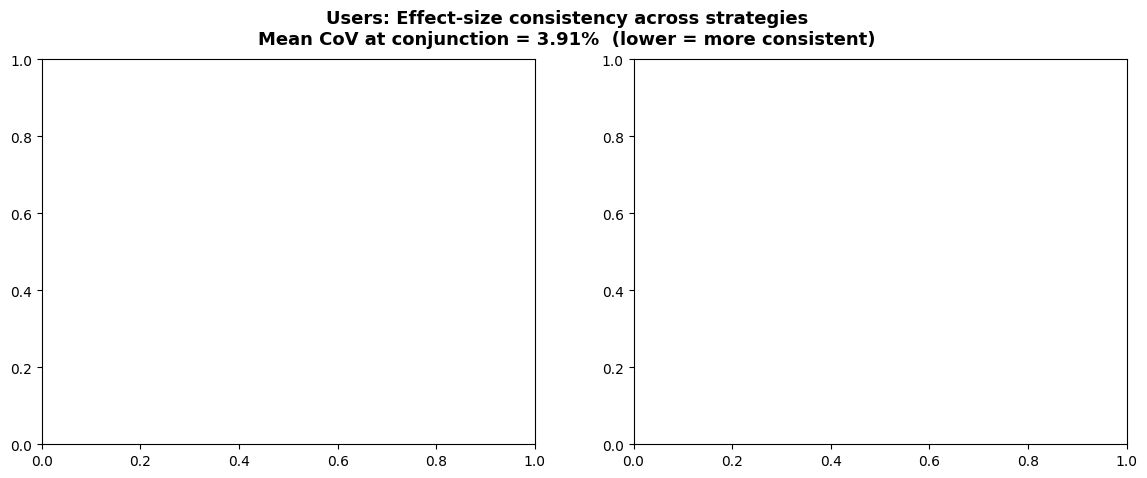

In [17]:
cmap_cov = plt.cm.viridis_r   # dark = high CoV (bad), light = low CoV (good)
out_dir_cov = "Figures/Flatmap/VBM/similarity/cov_maps"
os.makedirs(out_dir_cov, exist_ok=True)

for group in groups:
    cov_f   = f"{sim_dir}/{group}/cov_effectsize.nii.gz"
    mean_f  = f"{sim_dir}/{group}/mean_d_at_conjunction.nii.gz"
    mean_cov = get_nsig(group, 'mean_cov_conjunction')   # may be float, not int

    # Get scalar mean_cov from df
    r_cov = sim_df[(sim_df['group'] == group) & (sim_df['metric'] == 'mean_cov_conjunction')]['value']
    mean_cov_val = f"{r_cov.values[0]:.2f}" if len(r_cov) > 0 else "N/A"

    if not os.path.exists(cov_f):
        print(f"Missing CoV: {cov_f}")
        continue

    cov_surf  = flatmap.vol_to_surf(cov_f, space="SUIT")
    mean_surf = flatmap.vol_to_surf(mean_f, space="SUIT") if os.path.exists(mean_f) else None

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle(f"{group_labels[group]}: Effect-size consistency across strategies\n"
                 f"Mean CoV at conjunction = {mean_cov_val}%  (lower = more consistent)",
                 fontsize=13, fontweight='bold')

    flatmap.plot(data=cov_surf, cmap=cmap_cov,
                 cscale=[0, 50], new_figure=False,
                 undermap=undermap, bordersize=0.5,
                 render='matplotlib', axes=ax1)
    ax1.set_title("a) CoV (%) of Cohen's d\nacross strategies", fontsize=12)
    ax1.axis('off')

    if mean_surf is not None:
        flatmap.plot(data=mean_surf, cmap=cmap_d,
                     cscale=[-0.2, 0.2], new_figure=False,
                     undermap=undermap, underscale=[-100, 200],
                     bordersize=0.5, render='matplotlib')
    ax2.set_title("b) Mean Cohen's d at conjunction\n(cluster-corrected)", fontsize=12)
    ax2.axis('off')

    plt.tight_layout()
    fig.savefig(f"{out_dir_cov}/{group}_cov.png",
                dpi=300, transparent=True, bbox_inches='tight')
    plt.close(fig)

print(f"Saved CoV flatmaps → {out_dir_cov}")


## 8. Summary — Export File List

All figures are saved to `Figures/Flatmap/VBM/similarity/`. Summary of generated files.


In [ ]:
import glob

base = "Figures/Flatmap/VBM/similarity"
all_files = sorted(glob.glob(f"{base}/**/*.png", recursive=True))
print(f"\n{'='*60}")
print(f"EXPORT SUMMARY — {len(all_files)} PNG files generated")
print(f"{'='*60}")
for fp in all_files:
    size_kb = os.path.getsize(fp) // 1024 if os.path.exists(fp) else 0
    print(f"  {fp.replace(base+'/', '')}  [{size_kb} KB]")

print(f"\nFor manuscript: use 'conjunction_clustcorr_all_groups.png' (Figure 2)")
print("For supplementary: use per-group multi-method and per-strategy panels")
